In [1]:
%%html
<style>
div.optional {
    display: block;
    background-color: #d7e2ff;
    border-color: #d7e2ff;
    border-left: 5px solid #d7e2ff;
    padding: 0.5em;
}
div.advanced {
    display: block;
    background-color: #fff4d7;
    border-color: #fff4d7;
    border-left: 5px solid #fff4d7;
    padding: 0.5em;
}
</style>

In [2]:
%matplotlib inline
%precision 6
import numpy as np
import matplotlib.pyplot as plt
import scipy.linalg as sl
from pprint import pprint
# the following allows us to plot triangles indicating convergence order
from mpltools import annotation

# import Python's symbolic math library
import sympy as sym

# Computational Mathematics  <a class="tocSkip">

## Errors, verification & validation  <a class="tocSkip">
    
### Supplementary material on the method of manufactured solutions (MMS) <a class="tocSkip">

<h1>Table of Contents<span class="tocSkip"></span></h1>
<div class="toc"><ul class="toc-item"><li><span><a href="#The-Method-of-Manufactured-Solutions-(MMS)-[*---this-is-quite-involved,-and-specific-to-differential-equations,-so-read-through-please-if-this-is-an-area-you-plan-to-focus-on]" data-toc-modified-id="The-Method-of-Manufactured-Solutions-(MMS)-[*---this-is-quite-involved,-and-specific-to-differential-equations,-so-read-through-please-if-this-is-an-area-you-plan-to-focus-on]-1"><span class="toc-item-num">1&nbsp;&nbsp;</span>The Method of Manufactured Solutions (MMS) [* - this is quite involved, and specific to differential equations, so read through please if this is an area you plan to focus on]</a></span><ul class="toc-item"><li><span><a href="#A-simple-approach-for-an-ODE" data-toc-modified-id="A-simple-approach-for-an-ODE-1.1"><span class="toc-item-num">1.1&nbsp;&nbsp;</span>A simple approach for an ODE</a></span></li><li><span><a href="#An-approach-more-akin-to-how-we-would-perform-MMS-on-PDEs" data-toc-modified-id="An-approach-more-akin-to-how-we-would-perform-MMS-on-PDEs-1.2"><span class="toc-item-num">1.2&nbsp;&nbsp;</span>An approach more akin to how we would perform MMS on PDEs</a></span></li></ul></li></ul></div>


<div class="optional">

# The Method of Manufactured Solutions (MMS) [\* - this is quite involved, and specific to differential equations, so read through please if this is an area you plan to focus on]

Let's suppose for whatever reason we couldn't find a convenient exact solution - there just isn't one we can write down in analytic form, we don't know how to use symbolic tools, it's too difficult or we don't have time, ...

This is where the Method of Manufactured Solutions provides a very powerful and convenient approach.

Let's suppose we want to test our forward Euler code but we don't know anything about how to solve ODEs analytically.

Rather than starting from an equation and looking for a solution, the MMS approach starts from a "manufactured solution" and finds a corresponding equation (one that's very similar to the one we want to solve, and in verification of this we verify the code on the original).

We think to ourselves, what is a "non-trivial" solution - a solution that if our algorithm was able to recreate accurately we would be happy. 

By "trivial" I mean for our ODE solver to successfully recreate - for example $y=$constant, since then the RHS function is just zero, our code will get the answer correct exactly and we are not "stressing" our solver at all. We don't want this, we want a "non-trivial" solution.

Now this seems a stupid example, or that I am making an obvious point, but this is an issue we need to give appropriate care to in the case of PDEs - we may foolishly choose a solution that *looks* non-trivial but for which some of the terms in the PDE are actually zero (or very small compared to other terms), or exactly cancel for all numerical parameter choices - again we wouldn't be fully stressing all parts of our solver. So selection of an appropriate manufactured solution is an important part of the process, but shouldn't be that difficult with some trial and error, and turning terms on our solver on and off (and checking that the solution behaviour changes! If we turn a term on and off and the solution hardly changes, it indicates that that term wasn't doing much and the test we've come up with may not be a good one for it).

Next we will demonstrate the general approach with an ODE example.

Second we will repeat in a manner that is actually a bit closer to how we would perform MMS on PDEs.
    
</div>


<div class="optional">

## A simple approach for an ODE

We want to test our implementation of our code to solve the ODE problem

$$ y' = f(t,y), \qquad y(0)=y_0 $$

<br>

Let's start by writing down a function of $t$, this will be our "manufactured solution":

$$y(t) = 7\exp(t) - 3t^2 - 6t - 5, \qquad \text{for which} \qquad y(0) = 2$$

the next step in MMS is to substitute this into the LHS of the equation our code is designed to solve:

$$ y' =  \frac{dy}{dt} = 7\exp(t) - 6t - 6 $$

If we use this expression we have just derived as the RHS of our solver (i.e. the $f(t,y)$ function) then we have by construction the analytic solution to compare against.

Now we could of course code these two functions up ourselves and proceed, but if possible (as depending on what manufactured solution we choose, and what O/PDE we are solving, this could be extremely complicated and easy to make a mistake either in our derivation by hand or in the implementation in code) it makes sense to try and do this symbolically, i.e. here to use SymPy - we're only differentiating so it shouldn't have a problem with this.
    
</div>

In [3]:
t, y = sym.symbols('t, y')
y_ex = 7*sym.exp(t) - 3*t**2 - 6*t - 5
print(y_ex)
print(sym.diff(y_ex,t))

-3*t**2 - 6*t + 7*exp(t) - 5
-6*t + 7*exp(t) - 6


This is consistent with what we have above.

Let's turn these into functions and use both of them (as the RHS source term we give to the solver, and the analytic solution we compare the solution to) directly in a convergence analysis.

In [4]:
y_ex_fun = sym.lambdify(t, y_ex)
f = sym.lambdify((t,y), sym.diff(y_ex,t))
# f here is a function of t and y to be consistent with what our solver function expects
# even though the form of f we have derived is only dependent on t

# lambdify just turns the sympy expression into a function we can easily evaluate, e.g.
print(f(0,1))

1.0


In [5]:
# the forward Euler solver from the lecture notes (errors-verification-validation.ipynb)
def forward_euler(f, y0, t0, t_max, dt):
    """Forward Euler time stepper for y' = f(t, y); returns arrays of all y and t values."""
    y = np.array(y0)
    t = np.array(t0)
    y_all = [y0]
    t_all = [t0]
    while t < t_max:
        y = y_all[-1]
        y = y + dt * f(t, y)
        y_all.append(y)
        t = t + dt
        t_all.append(t)
    return np.array(y_all), np.array(t_all)

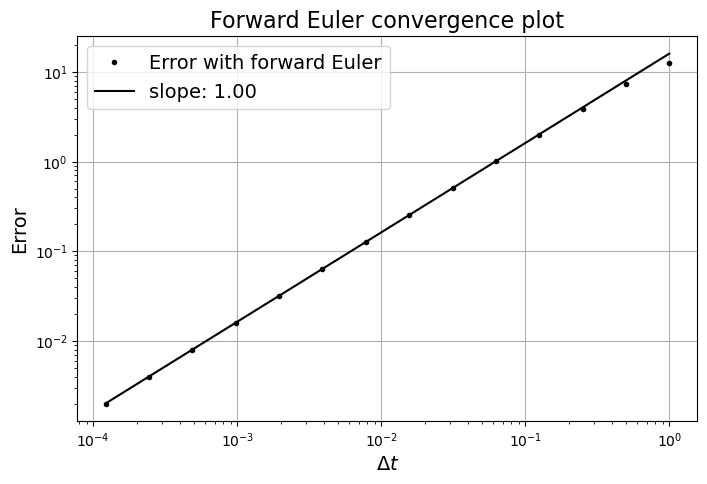

In [6]:
# now test convergence using this exact solution and the corresponding f function we've derived

t0 = 0.0
y0 = y_ex_fun(t0) 

error = []
dt_array = []

# an initial dt value
dt = 1.0

# the integration period
t_max = 2.0

# compute error in forward euler solution as dt varies
while dt > 1.e-4:
    dt_array.append(dt)
    y_all, t_all = forward_euler(f, y0, t0, t_max, dt)
    error.append(abs(y_all[-1] - y_ex_fun(t_max))) 
    dt *= 0.5


fig = plt.figure(figsize=(8, 5))
ax1 = plt.subplot(111)

# plot error vs dt with a log-log plot
ax1.loglog(dt_array, error, 'k.', label='Error with forward Euler')
ax1.set_xlabel(r'$\Delta t$', fontsize=14)
ax1.set_ylabel('Error', fontsize=14)
ax1.set_title('Forward Euler convergence plot', fontsize=16)
ax1.grid(True)

# use numpy.polyfit to find best fit linear line to data

start_fit = 3

line_fit = np.polyfit(np.log(dt_array[start_fit:]), np.log(error[start_fit:]), 1)
ax1.loglog(dt_array, np.exp(line_fit[1]) * dt_array**(line_fit[0]), 'k-', label = 'slope: {:.2f}'.format(line_fit[0]))

ax1.legend(loc='best', fontsize=14)

<div class="optional">

## An approach more akin to how we would perform MMS on PDEs

Now you may notice that in performing the above we have changed the problem we want to solve - our RHS function is now only a function of $t$, there is no $y$ dependence - we need to spot things like this as we may not be as rigorous (i.e. complete) in our testing as we think we are.

Of course we could use what we've done so far to rearrange (using that we know $y(t) = 7\exp(t) - 3t^2 - 6t - 5$):

$$ y' \equiv \dot{y} \equiv \frac{dy}{dt} = 7\exp(t) - 6t - 6 = y + 3t^2 -1$$

and perform the convergence analysis with

```Python
def f2(t, y):
    return y + 3*t**2 -1
```



If you use this for the RHS in the analysis above you will see that as expected we converge at the correct rate, but the errors are a little different - why? (Hint: refer back to the discussion of the forward Euler schematic from lecture 1).


<br>


However, the following is actually closer to what we would do with MMS for more general problems including PDEs. 

</div>

<div class="optional">
    
Let's suppose we have a solver (our forward Euler code will suffice), for the problem

$$ y' \equiv \dot{y} \equiv \frac{dy}{dt} = y$$

i.e. we have fixed the RHS.

Let's further suppose we don't know how to solve this problem analytically.

Rewrite the problem in terms of the (differential) operator:

$$L(y) = y'-y$$

$L(\cdot)$ is an operator and we know if we apply it to the exact solution we will get zero: $L(y_{\text{ex}}) = 0$, we might say that we have zero *residual* when plugging in the exact solution.


<br>


Now suppose we have a (manufactured) solution that isn't an exact solution: $y_{\text{mms}}$. 

Not being a solution is the same as saying that the residual is non-zero:

$$\text{residual} = L(y_{\text{mms}}) \ne 0$$

But of course $y_{\text{mms}}$ **is an exact solution to the modified problem**

$$y' - y = \text{residual}\qquad\text{or}\qquad y' = y+ \text{residual}$$

Since we choose $y_{\text{mms}}$ we can compute the appropriate derivatives etc contained in $L$ analytically and have an exact expression for the RHS residual - in typical O/PDE language we effectively have an **additional source term**.  

We simply update our code with this additional source term and conduct a convergence analysis using $y_{\text{mms}}$ as the exact solution.

Depending on whether our underlying solver already accepts a source term, we may or may not need to update the solver in order to perform this MMS analysis. But even if we do this is likely to be a relatively minor, and worthwhile update.

Further to this, we may be in a nice situation where our solver is in a language that also has symbolic capabilities so that we can automate most steps, which speeds things up and avoids us making silly errors in performing an MMS analysis.

For example:
    
</div>

In [7]:
# this is the new solver we want to check (the RHS is now:  y + source(t))

def our_solver(S, y0, t0, t_max, dt):
    """ A version of forward Euler that assumes our ODE 
    is of the form y' = y + source where source is 
    assumed to be a function of the form S(t)

    Parameters
    ----------
    S : callable
        The residual, L(y_ex) = y_ex' - y_ex
    y0 : float
        Exact value of y at time t0
    t0 : float
        Initial time
    t_max : float
        The last time step
    dt : float
        Time step size

    Returns
    -------
    tuple of ndarray
        Tuple containing numpy arrays for all y and t values within
        the specified interval
    """
    y = np.array(y0)
    t = np.array(t0)
    y_all = [y0]
    t_all = [t0]  
    while t < t_max:
        y = y_all[-1]
        y = y + dt * (y + S(t)) 
        y_all.append(y) 
        t = t + dt
        t_all.append(t)
    return np.array(y_all), np.array(t_all)


t = sym.symbols('t')

# try a more complicated manufactured solution
y_ex = 7*sym.exp(t) - 3*t**2 - 6*t - 5 + sym.cos(3*t) + sym.log(1+t)
print(y_ex)
# this is the corresponding residual (what will become our source):  L(y_ex) = y_ex' - y_ex
print(sym.diff(y_ex,t) - y_ex)

# turn these into functions we can use in our solver and testing
y_ex_fun = sym.lambdify(t, y_ex)
S = sym.lambdify(t, sym.diff(y_ex,t) - y_ex)

-3*t**2 - 6*t + 7*exp(t) + log(t + 1) + cos(3*t) - 5
3*t**2 - log(t + 1) - 3*sin(3*t) - cos(3*t) - 1 + 1/(t + 1)


<div class="optional">
    
For the first of these to be a solution we can compare our solver against, we need to use the second as our source term.

First let's plot this solution just to check it isn't trivial in some way that would mean it's not a good candidate to test our code.
  
</div>

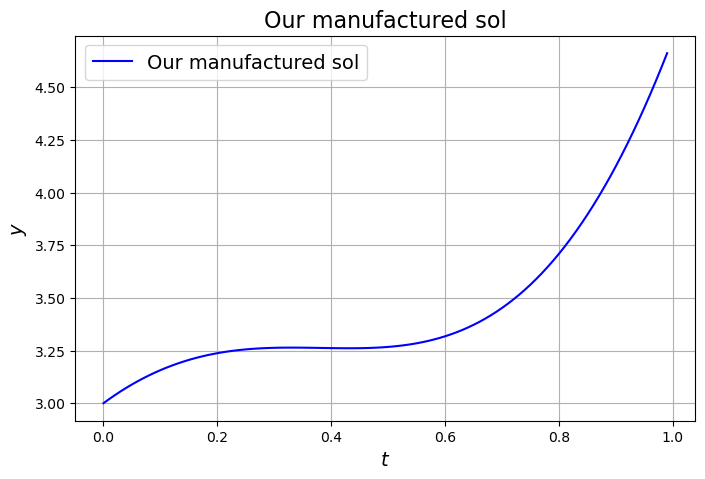

In [8]:
fig = plt.figure(figsize=(8, 5))
ax1 = plt.subplot(111)
t = np.arange(0, 1, 0.01)
ax1.plot(t,y_ex_fun(t), 'b', label='Our manufactured sol')
ax1.set_xlabel('$t$', fontsize=14)
ax1.set_ylabel('$y$', fontsize=14)
ax1.set_title('Our manufactured sol', fontsize=16)
ax1.grid(True)
ax1.legend(loc='best', fontsize=14)

<div class="optional">
    
Looks OK and is more complicated than the analytic solution we used earlier. 

Let's check convergence of our solver.
    
</div>

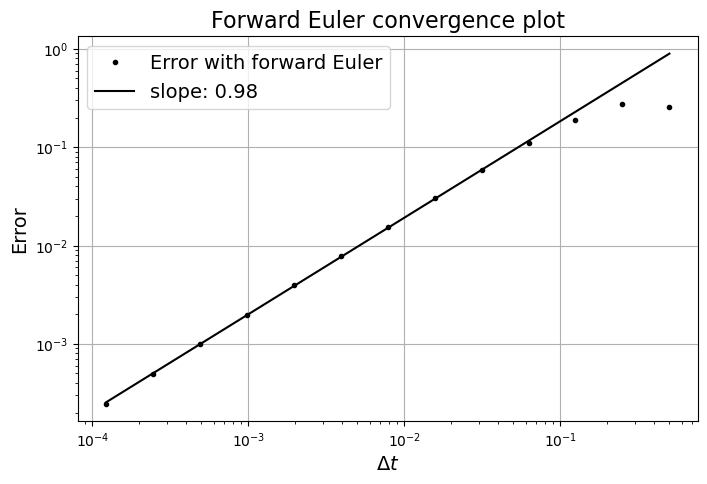

In [9]:
t0 = 0.0
y0 = y_ex_fun(t0)

error = []
dt_array = []

# an initial dt value
dt = 0.5

# the integration period
t_max = 1.0

# compute error in forward euler solution as dt varies
while dt > 1.e-4:
    dt_array.append(dt)
    y_all, t_all = our_solver(S, y0, t0, t_max, dt)
    error.append(abs(y_all[-1] - y_ex_fun(t_max))) 
    dt *= 0.5


fig = plt.figure(figsize=(8, 5))
ax1 = plt.subplot(111)

# plot error vs dt with a log-log plot
ax1.loglog(dt_array, error, 'k.', label='Error with forward Euler')
ax1.set_xlabel(r'$\Delta t$', fontsize=14)
ax1.set_ylabel('Error', fontsize=14)
ax1.set_title('Forward Euler convergence plot', fontsize=16)
ax1.grid(True)

# use numpy.polyfit to find best fit linear line to data

start_fit = 3

line_fit = np.polyfit(np.log(dt_array[start_fit:]), np.log(error[start_fit:]), 1)
ax1.loglog(dt_array, np.exp(line_fit[1]) * dt_array**(line_fit[0]), 'k-', label = 'slope: {:.2f}'.format(line_fit[0]))

ax1.legend(loc='best', fontsize=14)

<div class="optional">

In verifying convergence for the slightly more complicated problem (i.e. with the additional source term) we can conclude that our original solver has no bug that this test can detect (as the lecture notes stress, a test can show that a code is wrong, but never prove that it is right).

We can do this with a solution that allows us to test convergence holds (i.e. the errors keep reducing at the correct rate) down to very very small errors - helping identify subtle bugs that may be hard to identify if we use one of the other (non-analytic solution based) verification methods. MMS allows us to do this without the pain of needing to find an analytic solution - so particularly powerful for complicated problems where this may simply not be possible.
    
</div>